In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
import stim

import os 

while 'honeycomb.py' not in os.listdir():
    os.chdir("..")

from honeycomb import CSSHoneycomb
from operations import Detector

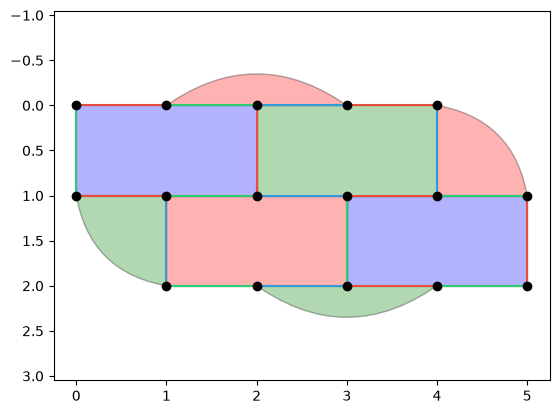

In [2]:
surface = CSSHoneycomb(5,3)
surface.plot_surface()

In [3]:
def plot_logicals(surface, X_coords, Z_coords, show=True, title=None):
    surface.plot_surface(show=False)

    xx, xy = zip(*X_coords)
    zx, zy = zip(*Z_coords)

    plt.plot(xx, xy, "-", c="red", linewidth=3, marker="o", markersize=10, label="X logical", zorder=10)
    plt.plot(zx, zy, "-", c="blue", linewidth=3, marker="o", markersize=10, label="Z logical", zorder=10)
    plt.legend()
    
    if title is not None:
        plt.title(title)

    if show:
        plt.show()

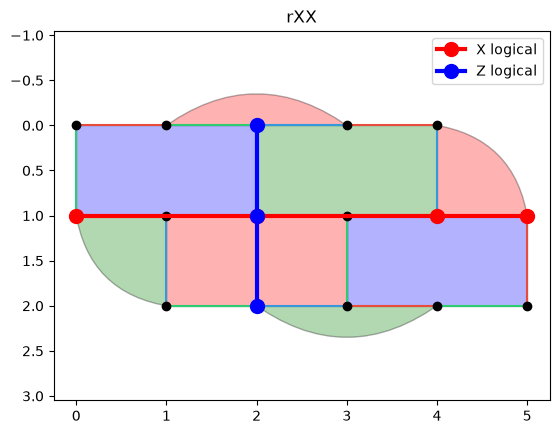

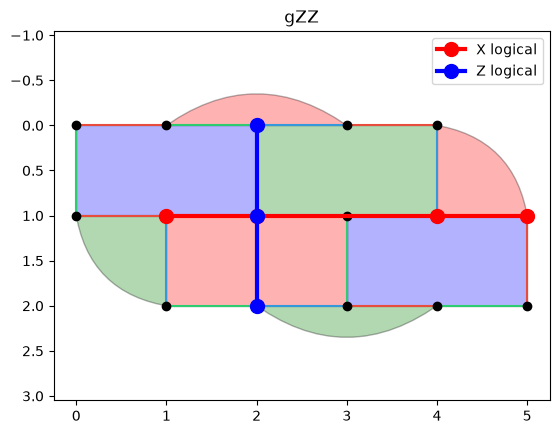

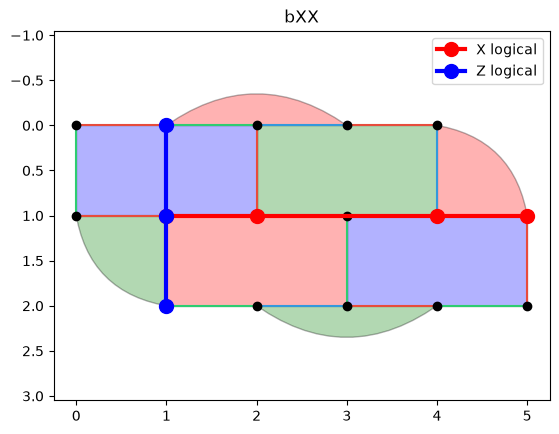

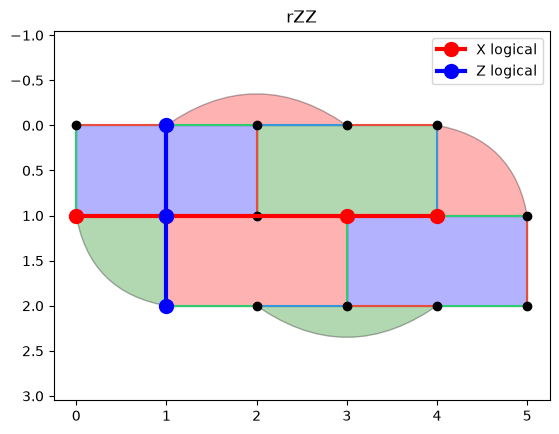

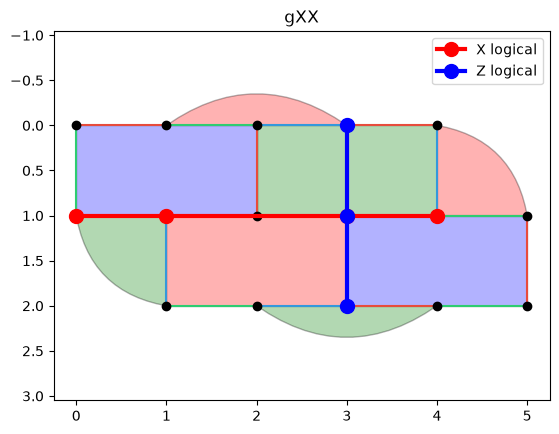

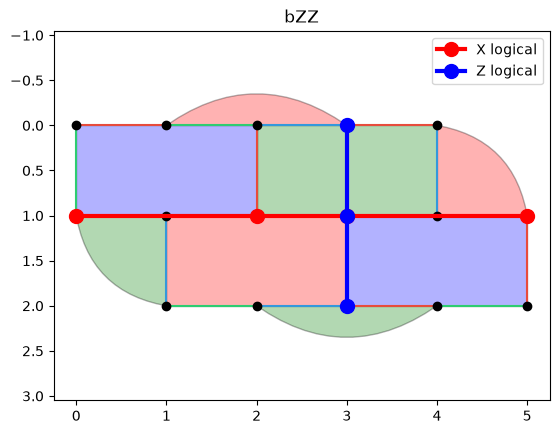

In [4]:
# rXX
X_coords = [
    (0, 1), (2, 1), (4, 1), (5, 1)
]
Z_coords = [
    (2, 0), (2, 1), (2, 2)
]
plot_logicals(surface, X_coords, Z_coords, title="rXX")

# gZZ
X_coords = [
    (1, 1), (2, 1), (4, 1), (5, 1)
]
Z_coords = Z_coords
plot_logicals(surface, X_coords, Z_coords, title="gZZ")

# bXX
X_coords = X_coords
Z_coords = [
    (1, 0), (1, 1), (1, 2)
]
plot_logicals(surface, X_coords, Z_coords, title="bXX")

# rZZ
X_coords = [
    (0,1),(1, 1),(3,1),(4,1)
]
Z_coords = Z_coords
plot_logicals(surface, X_coords, Z_coords, title="rZZ")

# gXX
X_coords = X_coords
Z_coords = [
    (3, 0), (3, 1), (3, 2)
]
plot_logicals(surface, X_coords, Z_coords, title="gXX")

# bZZ
X_coords = [
    (0, 1), (2, 1), (3, 1), (5, 1)
]
Z_coords = Z_coords
plot_logicals(surface, X_coords, Z_coords, title="bZZ")



In [5]:
c = stim.Circuit(surface.initialise_circuit())

c_prepare = stim.Circuit(surface.prepare_qubits())
c.append(c_prepare)

# rXX
X_coords = [
    (0, 1), (2, 1), (4, 1), (5, 1)
]
Z_coords = [
    (2, 0), (2, 1), (2, 2)
]
X_targets = [surface.qubit_coords[x_coord] for x_coord in X_coords]
Z_targets = [surface.qubit_coords[z_coord] for z_coord in Z_coords]

x_string = "MPP "
for t in X_targets:
    x_string += f"X{t}*"
x_string = x_string[:-1]
    
z_string = "MPP "
for t in Z_targets:
    z_string += f"Z{t}*"
z_string = z_string[:-1]

c.append(stim.Circuit(x_string + "\n" + z_string))


# gZZ
X_coords = [
    (1, 1), (2, 1), (4, 1), (5, 1)
]
Z_coords = Z_coords




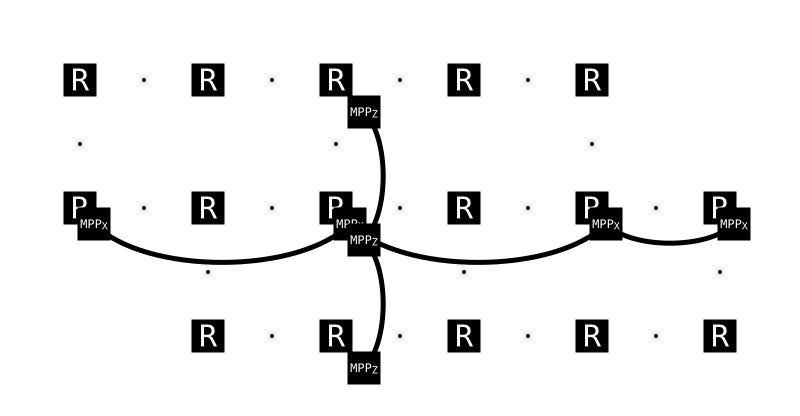

In [6]:
c.diagram("detslice-with-ops-svg")

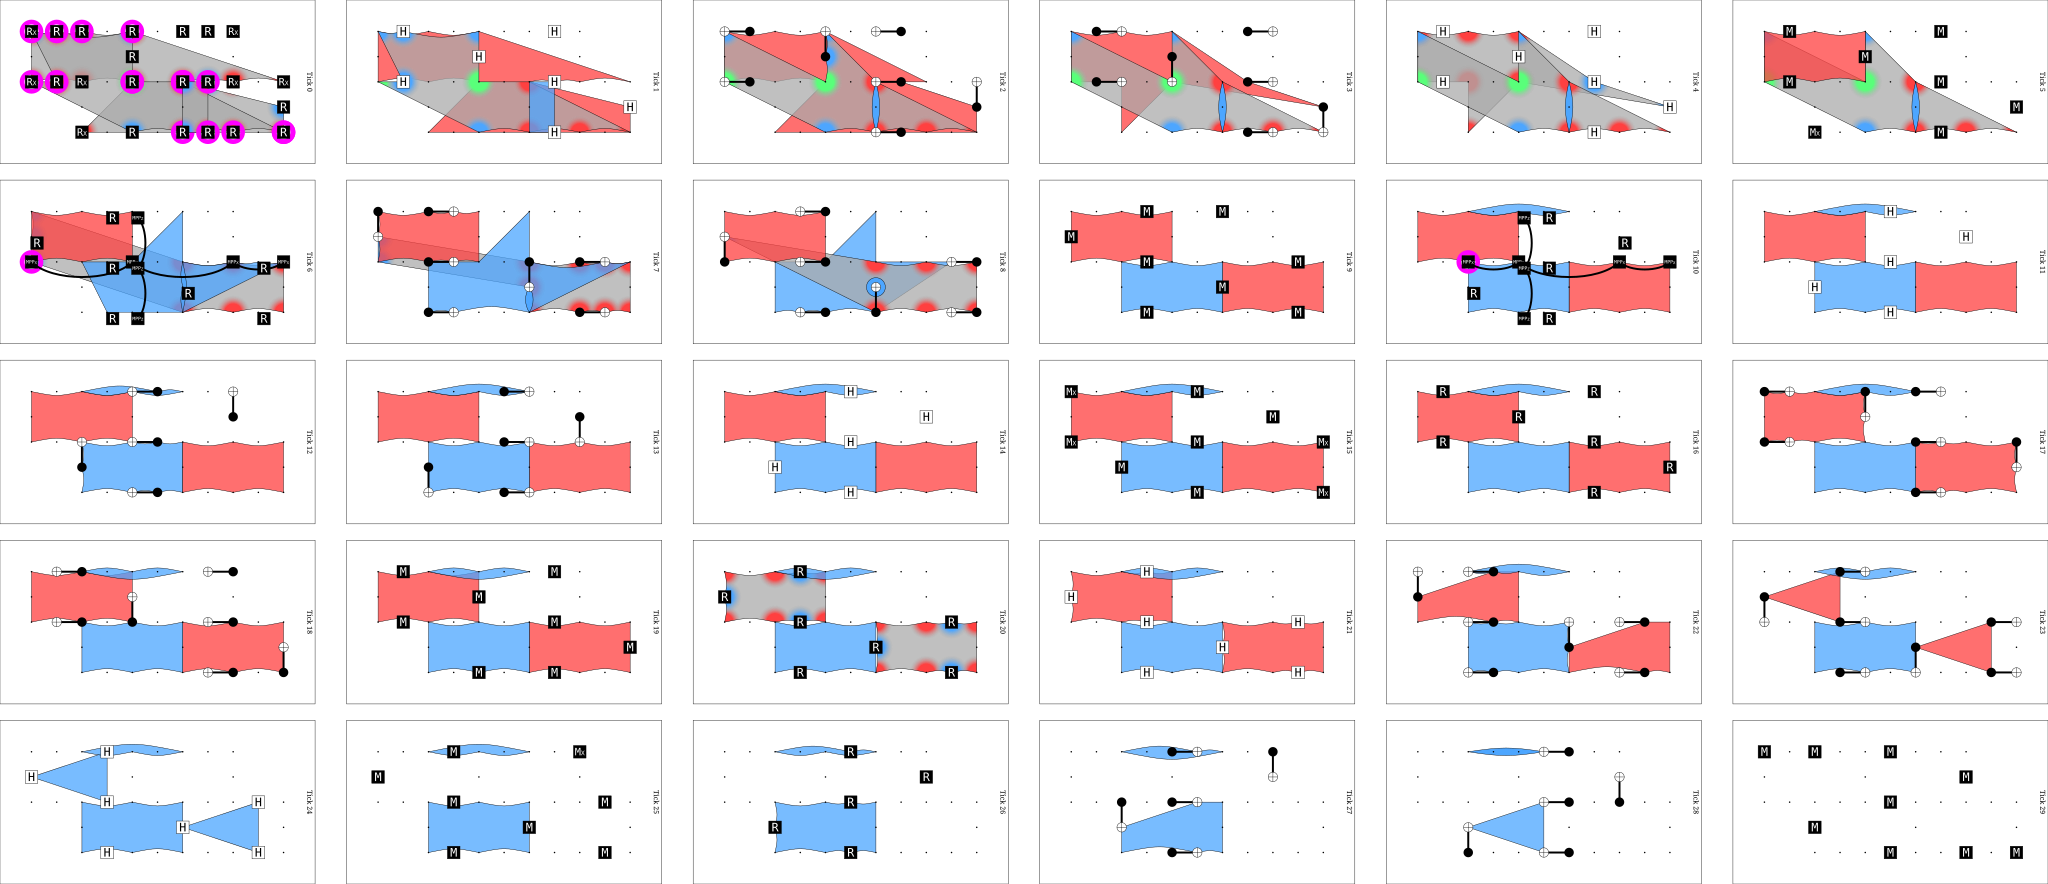

In [8]:
import json

def set_T_state(initialisation, flavour):
    for i, (q, init) in enumerate(initialisation):
        if init == "T":
            init = flavour

            initialisation[i] = (q, init)
    return initialisation

def write_prep_string(initialisation):
    x_string = "RX "
    z_string = "RZ "
    
    for q, state in initialisation:
        if state == "X":
            x_string += str(q) + " "
        if state == "Z":
            z_string += str(q) + " "
    
    string = x_string + "\n" + z_string
    return string

def write_logical(spec):
    x_logical = raw["logical_schedule"][spec]["X_logical"]
    z_logical = raw["logical_schedule"][spec]["Z_logical"]
    
    string = "MPP "
    for pos in x_logical:
        string += "X" + str(surface.qubit_coords[tuple(pos)]) + "*"
    string = string[:-1] + "\nMPP "
    
    for pos in z_logical:
        string += "Z" + str(surface.qubit_coords[tuple(pos)]) + "*"
    string = string[:-1] + "\n"
    
    return string
    
    

surface = CSSHoneycomb(ncols=5, nrows=3)
c = stim.Circuit(surface.initialise_circuit())


raw = json.load(open("preparation/surface_d3.json"))
initialisation = [(surface.qubit_coords[tuple(q["pos"])], q["init"]) for q in raw["qubits"]]
initialisation = set_T_state(initialisation, "Z") # use this to set to basis state for simlation

# print(initialisation)

c_prepare = stim.Circuit(write_prep_string(initialisation))
c.append(c_prepare)

c_rXX = stim.Circuit(surface.get_measurement("red", "X") + surface.tick() + write_logical("rXX"))
c.append(c_rXX)

c_gZZ = stim.Circuit(surface.get_measurement("green", "Z") + surface.tick() + write_logical("gZZ"))
c.append(c_gZZ)

c_bXX = stim.Circuit(surface.get_measurement("blue", "X") + surface.tick())
c.append(c_bXX)

c_rZZ = stim.Circuit(surface.get_measurement("red", "Z") + surface.tick())
c.append(c_rZZ)

c_gXX = stim.Circuit(surface.get_measurement("green", "X") + surface.tick())
c.append(c_gXX)

c_bZZ = stim.Circuit(surface.get_measurement("blue", "Z") + surface.tick())
c.append(c_bZZ)

c.diagram("detslice-with-ops-svg")

This ^ generates fucked detecting regions because I am measuring logicals which is messing with the measurement record. I am not adding logcial measurements to the CSSHoneycomb record but stim is recording them.

We only want to readout logicals at the end of our sim.